<a href="https://colab.research.google.com/github/saniaishaq1017-debug/Sania.github.io/blob/main/Copy_of_Untitled6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install rdkit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 31.8/31.8 MB 37.7 MB/s  0:00:00


In [ ]:
import networkx as nx
import numpy as np
from rdkit import Chem
from rdkit.Chem import Descriptors

# Brain Tumor Sample Drugs (SMILES Dataset)
brain_tumor_drugs = {
    "Temozolomide": "CN1C(=O)N2C(=N1)C(=O)NC2=N",
    "Carmustine": "O=N(N(CCCl)C(=O)NCCCl)",
    "Lomustine": "O=N(N(CCCl)C(=O)NC1CCCCC1)"
}

def analyze_drug_graphs(smiles_dict, neglect_double_bonds=False):
    results_summary = {}

    for name, smiles in smiles_dict.items():
        mol = Chem.MolFromSmiles(smiles)
        if mol is None:
            continue

        # i. Graph's Construction using NetworkX
        G = nx.Graph()
        for atom in mol.GetAtoms():
            G.add_node(atom.GetIdx(), element=atom.GetSymbol())

        for bond in mol.GetBonds():
            u = bond.GetBeginAtomIdx()
            v = bond.GetEndAtomIdx()
            weight = 1 if neglect_double_bonds else bond.GetBondTypeAsDouble()
            G.add_edge(u, v, weight=weight)

        n = G.number_of_nodes()
        m = G.number_of_edges()

        # Matrices Construction
        A = nx.adjacency_matrix(G, weight='weight').toarray()
        L = nx.laplacian_matrix(G, weight='weight').toarray()

        # Spectral Analyses
        eig_A = np.linalg.eigvalsh(A)
        eig_L = np.linalg.eigvalsh(L)

        degrees = dict(G.degree(weight='weight' if not neglect_double_bonds else None))
        deg_vals = list(degrees.values())

        # ii. Computing 15 to 20 Topological Indices & Spectra
        path_lengths = dict(nx.all_pairs_shortest_path_length(G))

        wiener = sum(sum(lengths.values()) for u, lengths in path_lengths.items()) / 2 if nx.is_connected(G) else float('inf')
        m1 = sum(d**2 for d in deg_vals)
        m2 = sum(degrees[u] * degrees[v] for u, v in G.edges())
        randic = sum((degrees[u] * degrees[v])**(-0.5) for u, v in G.edges() if degrees[u]*degrees[v] > 0)

        indices = {
            "1. Wiener Index": wiener,
            "2. First Zagreb Index (M1)": m1,
            "3. Second Zagreb Index (M2)": m2,
            "4. Randić Connectivity Index": randic,
            "5. Reciprocal Wiener Index": sum(1/path_lengths[u][v] for u in path_lengths for v in path_lengths[u] if u != v and path_lengths[u][v] > 0)/2 if nx.is_connected(G) else 0,
            "6. Estrada Index": sum(np.exp(eig_A)),
            "7. Laplacian Energy": sum(np.abs(eig_L - np.mean(eig_L))),
            "8. Algebraic Connectivity (Fiedler Value)": sorted(eig_L)[1] if n > 1 else 0,
            "9. Graph Energy (Adjacency Spectrum Sum)": sum(np.abs(eig_A)),
            "10. Adjacency Matrix Trace": np.trace(A),
            "11. Maximum Degree": max(deg_vals) if deg_vals else 0,
            "12. Minimum Degree": min(deg_vals) if deg_vals else 0,
            "13. Average Degree": sum(deg_vals) / n if n > 0 else 0,
            "14. Graph Diameter": nx.diameter(G) if nx.is_connected(G) and n > 0 else float('inf'),
            "15. Graph Radius": nx.radius(G) if nx.is_connected(G) and n > 0 else float('inf'),
            "16. Vertex Connectivity": nx.node_connectivity(G) if n > 1 else 0,
            "17. Edge Connectivity": nx.edge_connectivity(G) if n > 0 else 0,
            "18. Number of Nodes (Order)": n,
            "19. Number of Edges (Size)": m,
            "20. Spectral Radius": max(np.abs(eig_A)) if len(eig_A) > 0 else 0
        }

        # iii. Computation Validations
        assert np.allclose(A, A.T), f"Adjacency matrix symmetry failed for {name}"
        assert np.allclose(L, L.T), f"Laplacian matrix symmetry failed for {name}"

        results_summary[name] = indices

    return results_summary

# Normal Analysis (With Double Bonds / Bond Multiplicity)
print("=== NORMAL ANALYSIS (WITH DOUBLE BONDS) ===")
normal_results = analyze_drug_graphs(brain_tumor_drugs, neglect_double_bonds=False)
for drug, ind in normal_results.items():
    print(f"\nDrug: {drug}")
    for k, v in list(ind.items())[:5]:
        print(f"  {k}: {v:.4f}" if isinstance(v, float) else f"  {k}: {v}")

# Analysis after Neglecting Double Bonds
print("\n=== ANALYSIS AFTER NEGLECTING DOUBLE BONDS ===")
neglected_results = analyze_drug_graphs(brain_tumor_drugs, neglect_double_bonds=True)
for drug, ind in neglected_results.items():
    print(f"\nDrug: {drug} (Neglected Double Bonds)")
    for k, v in list(ind.items())[:5]:
        print(f"  {k}: {v:.4f}" if isinstance(v, float) else f"  {k}: {v}")

=== NORMAL ANALYSIS (WITH DOUBLE BONDS) ===

Drug: Temozolomide
  1. Wiener Index: 171.0000
  2. First Zagreb Index (M1): 131.0000
  3. Second Zagreb Index (M2): 158.0000
  4. Randić Connectivity Index: 4.0050
  5. Reciprocal Wiener Index: 32.5500

Drug: Carmustine
  1. Wiener Index: 226.0000
  2. First Zagreb Index (M1): 64.0000
  3. Second Zagreb Index (M2): 65.0000
  4. Randić Connectivity Index: 5.0598
  5. Reciprocal Wiener Index: 27.5202

Drug: Lomustine
  1. Wiener Index: 402.0000
  2. First Zagreb Index (M1): 84.0000
  3. Second Zagreb Index (M2): 89.0000
  4. Randić Connectivity Index: 6.5775
  5. Reciprocal Wiener Index: 40.3873

=== ANALYSIS AFTER NEGLECTING DOUBLE BONDS ===

Drug: Temozolomide (Neglected Double Bonds)
  1. Wiener Index: 171.0000
  2. First Zagreb Index (M1): 66
  3. Second Zagreb Index (M2): 81
  4. Randić Connectivity Index: 5.6091
  5. Reciprocal Wiener Index: 32.5500

Drug: Carmustine (Neglected Double Bonds)
  1. Wiener Index: 226.0000
  2. First Zagreb

In [ ]:
import networkx as nx
from rdkit import Chem

# Brain Tumor Sample Drugs (SMILES)
drugs = {
    "Temozolomide": "CN1C(=O)N2C(=N1)C(=O)NC2=N",
    "Carmustine": "O=N(N(CCCl)C(=O)NCCCl)",
    "Lomustine": "O=N(N(CCCl)C(=O)NC1CCCCC1)"
}

for name, smiles in drugs.items():
    # RDKit se molecule object banana
    mol = Chem.MolFromSmiles(smiles)

    # NetworkX ka undirected graph initialize karna
    G = nx.Graph()

    # 1. Nodes (Atoms) add karna
    for atom in mol.GetAtoms():
        G.add_node(atom.GetIdx(), element=atom.GetSymbol())

    # 2. Edges (Bonds with multiplicity weight) add karna
    for bond in mol.GetBonds():
        u = bond.GetBeginAtomIdx()
        v = bond.GetEndAtomIdx()
        bond_order = bond.GetBondTypeAsDouble() # 1.0 for single, 2.0 for double, etc.
        G.add_edge(u, v, weight=bond_order)

    print(f"Compound: {name}")
    print(f"  - Total Nodes (Atoms): {G.number_of_nodes()}")
    print(f"  - Total Edges (Bonds): {G.number_of_edges()}")
    print("-" * 40)

Compound: Temozolomide
  - Total Nodes (Atoms): 12
  - Total Edges (Bonds): 13
----------------------------------------
Compound: Carmustine
  - Total Nodes (Atoms): 12
  - Total Edges (Bonds): 11
----------------------------------------
Compound: Lomustine
  - Total Nodes (Atoms): 15
  - Total Edges (Bonds): 15
----------------------------------------


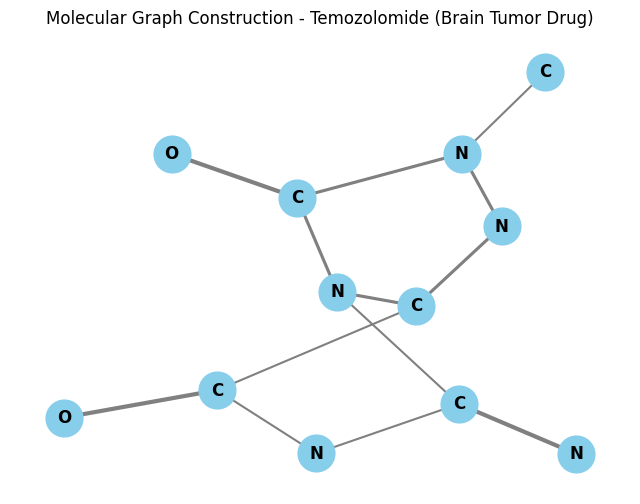

In [ ]:
import networkx as nx
import matplotlib.pyplot as plt
from rdkit import Chem

# Temozolomide SMILES as a sample drug
smiles = "CN1C(=O)N2C(=N1)C(=O)NC2=N"
mol = Chem.MolFromSmiles(smiles)

# Graph Construction
G = nx.Graph()
for atom in mol.GetAtoms():
    G.add_node(atom.GetIdx(), element=atom.GetSymbol())

for bond in mol.GetBonds():
    u = bond.GetBeginAtomIdx()
    v = bond.GetEndAtomIdx()
    weight = bond.GetBondTypeAsDouble()
    G.add_edge(u, v, weight=weight)

# Node labels (Atom symbols mapping)
labels = nx.get_node_attributes(G, 'element')

# Visual Plotting
plt.figure(figsize=(8, 6))
pos = nx.spring_layout(G, seed=42) # Layout for clear node distribution

# Draw nodes and labels
nx.draw_networkx_nodes(G, pos, node_size=700, node_color='skyblue')
nx.draw_networkx_labels(G, pos, labels, font_size=12, font_weight='bold')

# Draw edges (with different thickness based on bond order/weight)
edges = G.edges(data=True)
weights = [ed['weight'] * 1.5 for u, v, ed in edges]
nx.draw_networkx_edges(G, pos, width=weights, edge_color='gray')

plt.title("Molecular Graph Construction - Temozolomide (Brain Tumor Drug)", fontsize=12)
plt.axis('off')
plt.show()